In [19]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import random

def polygon_to_bbox(points):
    xs = points[::2]
    ys = points[1::2]
    return np.array(xs), np.array(ys)

def polygon_perimeter(xs, ys):
    pts = np.array(list(zip(xs, ys)) + [(xs[0], ys[0])])
    return np.sum(np.sqrt(np.sum(np.diff(pts, axis=0)**2, axis=1)))

def load_image_and_polygons(image_path):
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_h, img_w, _ = img.shape

    label_path = image_path.replace('images', 'labelTxt').replace('.jpg', '.txt').replace('.png', '.txt')
    polygons = []
    classes = []
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f.readlines():
                parts = line.strip().split()
                coords = list(map(float, parts[:-2]))  # all but last two items are coords
                class_name = parts[-2]
                class_id = 0  # update if multiple classes
                polygons.append(coords)
                classes.append(class_id)
    return img, polygons, classes

def plot_polygons(img, polygons, classes):
    plt.figure(figsize=(10,10))
    plt.imshow(img)
    ax = plt.gca()

    for poly, cls in zip(polygons, classes):
        xs, ys = polygon_to_bbox(poly)
        poly_points = np.array([[x, y] for x, y in zip(xs, ys)])
        patch = plt.Polygon(poly_points, closed=True, fill=False, edgecolor='lime', linewidth=2)
        ax.add_patch(patch)
        ax.text(xs[0], ys[0], f"Class {cls}", color='white', fontsize=12,
                bbox=dict(facecolor='green', alpha=0.5))
    plt.axis('off')
    plt.show()

Visualizing sample images with polygons:


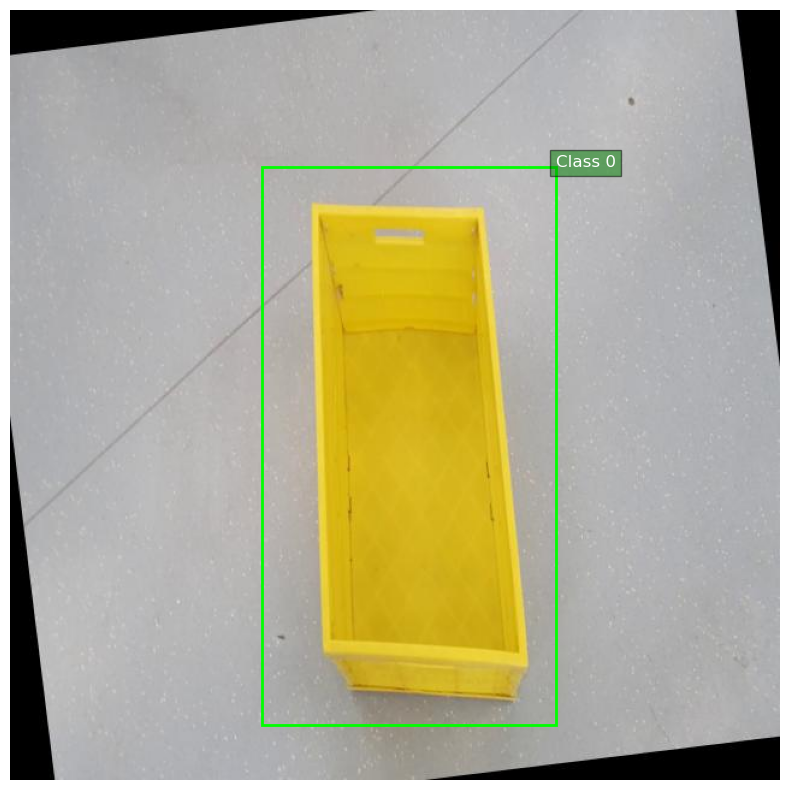

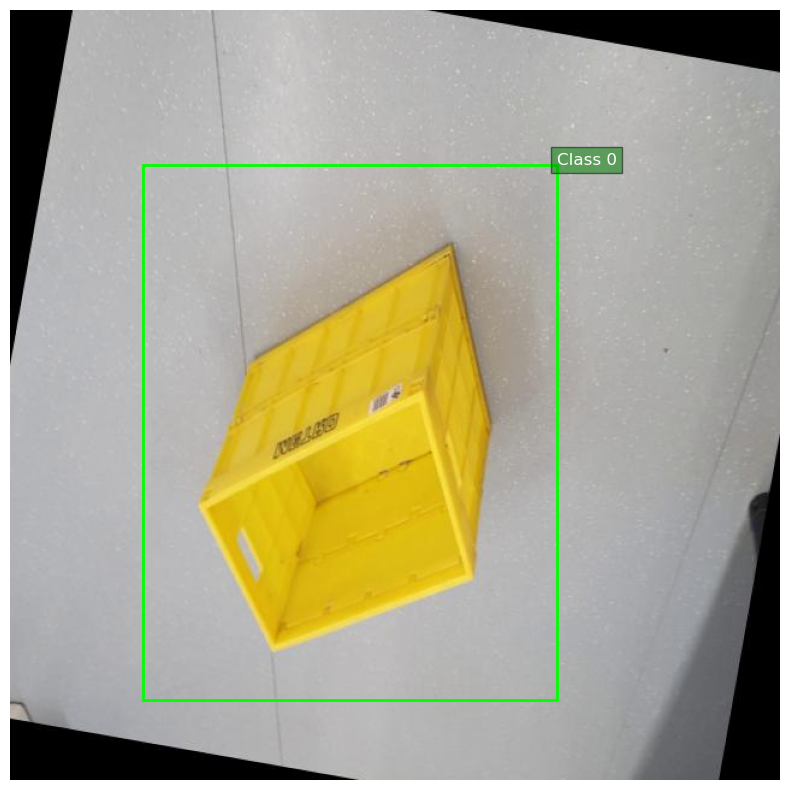

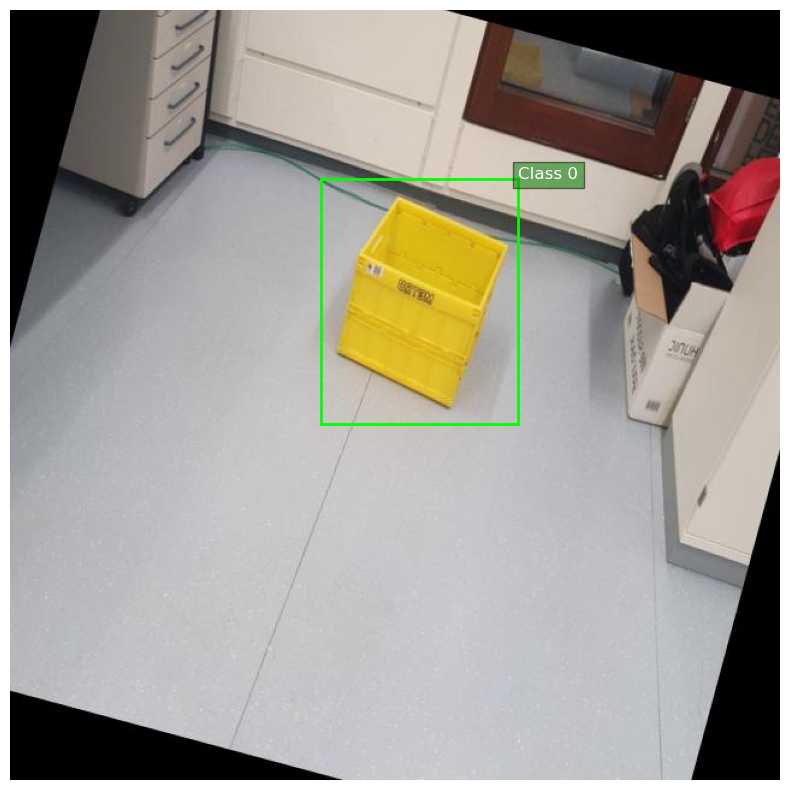

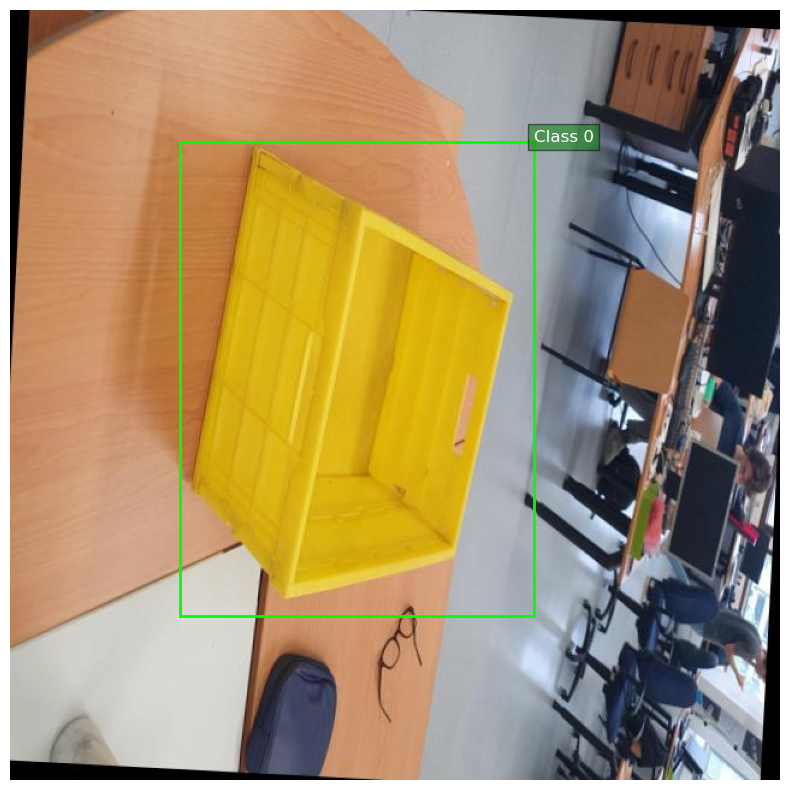

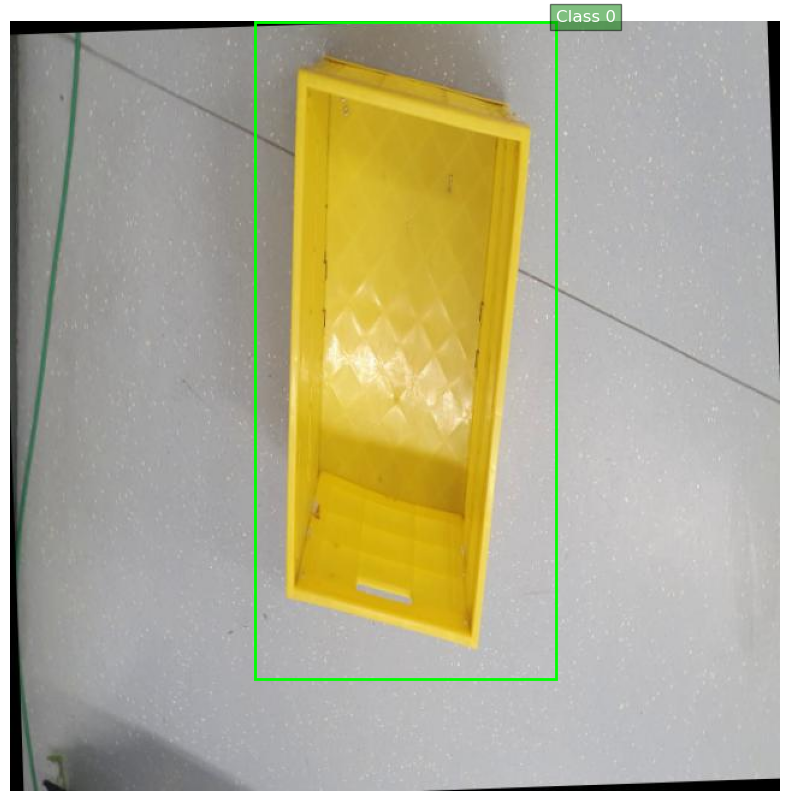

In [20]:
# Load sample images
train_path = 'train/images'  
image_files = [os.path.join(train_path, f) for f in os.listdir(train_path) if f.endswith(('.jpg','.png'))]
sample_images = random.sample(image_files, 5)

print("Visualizing sample images with polygons:")
for img_path in sample_images:
    img, polygons, classes = load_image_and_polygons(img_path)
    plot_polygons(img, polygons, classes)

In [21]:
# Statistics calculations
def polygon_bbox_area(xs, ys):
    # Shoelace formula for polygon area
    return 0.5 * abs(np.dot(xs, np.roll(ys, 1)) - np.dot(ys, np.roll(xs, 1)))

def load_all_polygon_stats(label_folder):
    areas = []
    perimeters = []
    for root, _, files in os.walk(label_folder):
        for f in files:
            if f.endswith('.txt'):
                label_path = os.path.join(root, f)
                with open(label_path, 'r') as file:
                    for line in file.readlines():
                        parts = line.strip().split()
                        coords = list(map(float, parts[:-2]))
                        xs = np.array(coords[::2])
                        ys = np.array(coords[1::2])
                        area = polygon_bbox_area(xs, ys)
                        perimeter = polygon_perimeter(xs, ys)
                        areas.append(area)
                        perimeters.append(perimeter)
    return areas, perimeters

label_folder = train_path.replace('images', 'labelTxt')
areas, perimeters = load_all_polygon_stats(label_folder)

print(f"Total polygons (boxes) in training set: {len(areas)}")

Total polygons (boxes) in training set: 2125


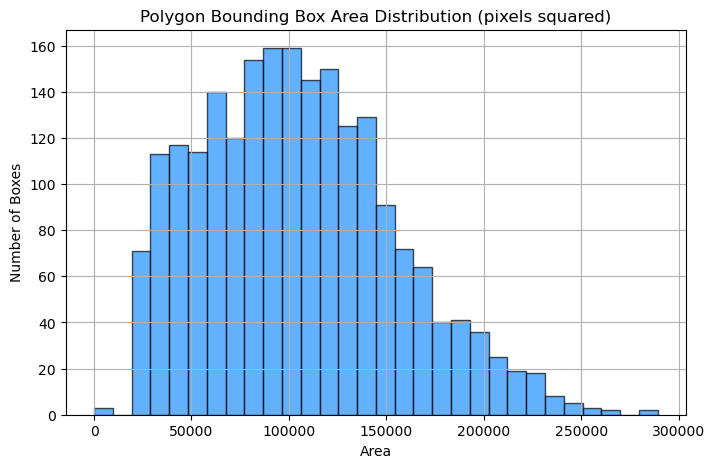

In [22]:
# Plot area distribution
plt.figure(figsize=(8,5))
plt.hist(areas, bins=30, color='dodgerblue', edgecolor='black', alpha=0.7)
plt.title('Polygon Bounding Box Area Distribution (pixels squared)')
plt.xlabel('Area')
plt.ylabel('Number of Boxes')
plt.grid(True)
plt.show()

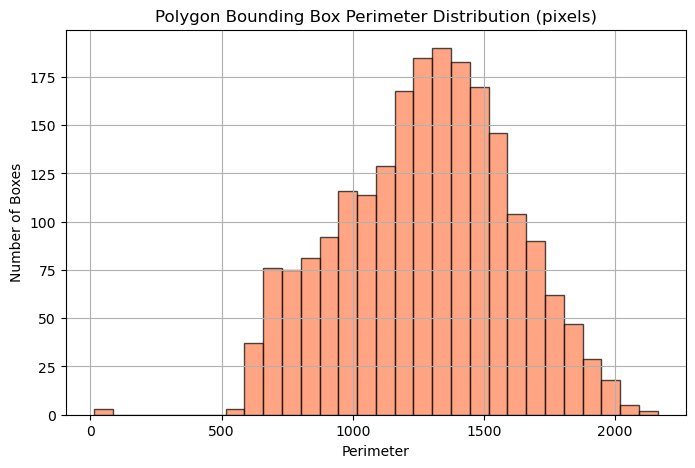

In [23]:
# Plot perimeter distribution
plt.figure(figsize=(8,5))
plt.hist(perimeters, bins=30, color='coral', edgecolor='black', alpha=0.7)
plt.title('Polygon Bounding Box Perimeter Distribution (pixels)')
plt.xlabel('Perimeter')
plt.ylabel('Number of Boxes')
plt.grid(True)
plt.show()

In [24]:
# Boxes per image distribution
def boxes_per_image(label_folder):
    counts = []
    for root, _, files in os.walk(label_folder):
        for f in files:
            if f.endswith('.txt'):
                label_path = os.path.join(root, f)
                with open(label_path, 'r') as file:
                    count = len(file.readlines())
                    counts.append(count)
    return counts

counts = boxes_per_image(label_folder)
print(f"Average boxes per image: {np.mean(counts):.2f}")

Average boxes per image: 1.00


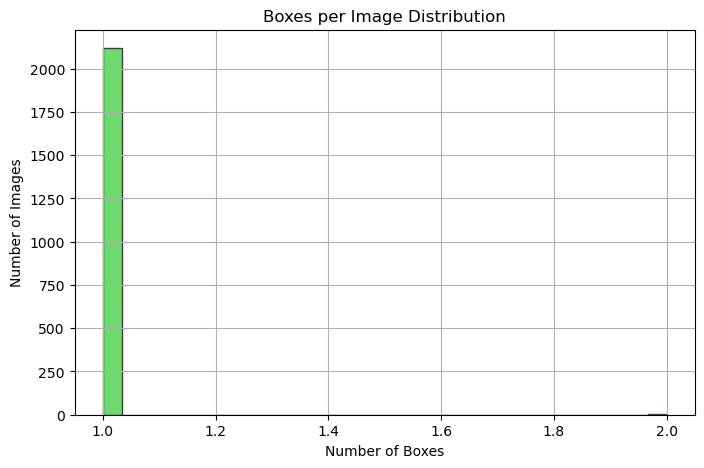

In [25]:
plt.figure(figsize=(8,5))
plt.hist(counts, bins=30, color='limegreen', edgecolor='black', alpha=0.7)
plt.title('Boxes per Image Distribution')
plt.xlabel('Number of Boxes')
plt.ylabel('Number of Images')
plt.grid(True)
plt.show()

In [26]:
# Image resolution stats
def image_resolutions(image_folder):
    widths = []
    heights = []
    for root, _, files in os.walk(image_folder):
        for f in files:
            if f.endswith(('.jpg', '.png')):
                image_path = os.path.join(root, f)
                img = cv2.imread(image_path)
                if img is not None:
                    h, w = img.shape[:2]
                    widths.append(w)
                    heights.append(h)
    return widths, heights

widths, heights = image_resolutions(train_path)
print(f"Image resolution stats (Train): mean width={np.mean(widths):.1f}, mean height={np.mean(heights):.1f}")

Image resolution stats (Train): mean width=640.0, mean height=640.0


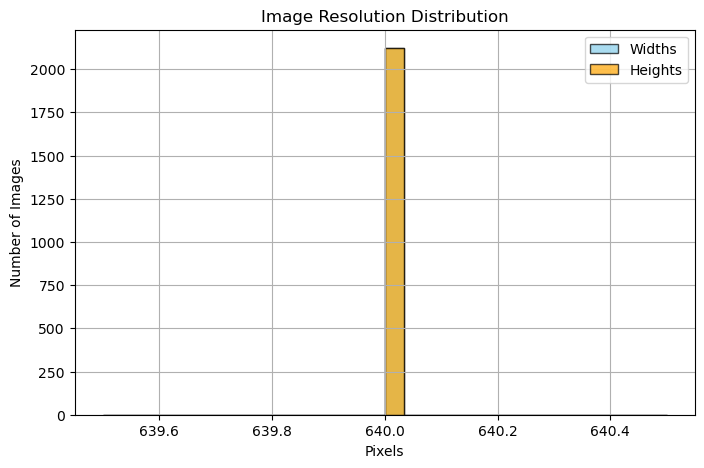

In [27]:
plt.figure(figsize=(8,5))
plt.hist(widths, bins=30, color='skyblue', edgecolor='black', alpha=0.7, label='Widths')
plt.hist(heights, bins=30, color='orange', edgecolor='black', alpha=0.7, label='Heights')
plt.title('Image Resolution Distribution')
plt.xlabel('Pixels')
plt.ylabel('Number of Images')
plt.legend()
plt.grid(True)
plt.show()

In [29]:
# Correlation: Box area vs boxes per image
import pandas as pd

df_stats = pd.DataFrame({'area': areas, 'perimeter': perimeters})
print(f"Correlation between box area and perimeter: {df_stats.corr().loc['area', 'perimeter']:.3f}")

Correlation between box area and perimeter: 0.983


TRAIN:
  Number of images: 2122
  Total boxes: 2125
  Average boxes per image: 1.00

VALID:
  Number of images: 202
  Total boxes: 202
  Average boxes per image: 1.00

TEST:
  Number of images: 102
  Total boxes: 102
  Average boxes per image: 1.00



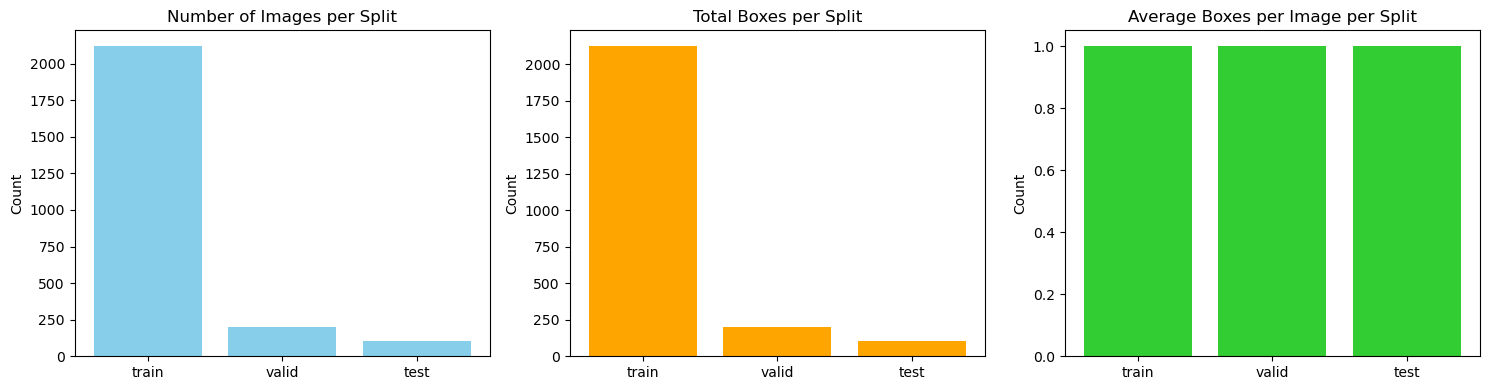

In [33]:
def count_images_and_boxes(images_path, labels_path):
    image_files = [f for f in os.listdir(images_path) if f.endswith(('.jpg', '.png'))]
    num_images = len(image_files)

    box_counts = []
    for label_file in os.listdir(labels_path):
        if label_file.endswith('.txt'):
            with open(os.path.join(labels_path, label_file), 'r') as f:
                lines = f.readlines()
                box_counts.append(len(lines))
    total_boxes = sum(box_counts)
    avg_boxes_per_image = np.mean(box_counts) if box_counts else 0
    return num_images, total_boxes, avg_boxes_per_image

def print_and_plot_distribution(dataset_root):
    splits = ['train', 'valid', 'test']
    stats = {'split': [], 'num_images': [], 'total_boxes': [], 'avg_boxes_per_image': []}

    for split in splits:
        images_path = os.path.join(dataset_root, split, 'images')
        labels_path = os.path.join(dataset_root, split, 'labelTxt')
        num_images, total_boxes, avg_boxes = count_images_and_boxes(images_path, labels_path)
        stats['split'].append(split)
        stats['num_images'].append(num_images)
        stats['total_boxes'].append(total_boxes)
        stats['avg_boxes_per_image'].append(avg_boxes)
        print(f"{split.upper()}:")
        print(f"  Number of images: {num_images}")
        print(f"  Total boxes: {total_boxes}")
        print(f"  Average boxes per image: {avg_boxes:.2f}\n")

    # Plot bar charts
    x = stats['split']
    plt.figure(figsize=(15,4))

    plt.subplot(1,3,1)
    plt.bar(x, stats['num_images'], color='skyblue')
    plt.title('Number of Images per Split')
    plt.ylabel('Count')

    plt.subplot(1,3,2)
    plt.bar(x, stats['total_boxes'], color='orange')
    plt.title('Total Boxes per Split')
    plt.ylabel('Count')

    plt.subplot(1,3,3)
    plt.bar(x, stats['avg_boxes_per_image'], color='limegreen')
    plt.title('Average Boxes per Image per Split')
    plt.ylabel('Count')

    plt.tight_layout()
    plt.show()

# Replace with your dataset root path
dataset_root = '.'
print_and_plot_distribution(dataset_root)
